In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc
)

print("Библиотеки успешно загружены!")

Библиотеки успешно загружены!


In [2]:
# Загружаем датасет Breast Cancer Wisconsin

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

print("Размер X:", X.shape)
print("Количество объектов:", len(y))
print("\nИсходное распределение классов:")
print(y.value_counts())

Размер X: (569, 30)
Количество объектов: 569

Исходное распределение классов:
1    357
0    212
Name: count, dtype: int64


In [4]:
# Преобразуем целевую переменную
# 0 — доброкачественная опухоль
# 1 — злокачественная опухоль

y = 1 - y

print("Распределение классов после преобразования:")
print(y.value_counts())

print("\n0 — доброкачественная")
print("1 — злокачественная")

Распределение классов после преобразования:
0    357
1    212
Name: count, dtype: int64

0 — доброкачественная
1 — злокачественная


In [5]:
# Разделяем данные на обучающую и тестовую выборки

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

print("\nКлассы в обучающей выборке:")
print(y_train.value_counts())

print("\nКлассы в тестовой выборке:")
print(y_test.value_counts())

Размер обучающей выборки: (455, 30)
Размер тестовой выборки: (114, 30)

Классы в обучающей выборке:
0    285
1    170
Name: count, dtype: int64

Классы в тестовой выборке:
0    72
1    42
Name: count, dtype: int64


In [6]:
# Стандартизируем признаки

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размер X_train_scaled:", X_train_scaled.shape)
print("Размер X_test_scaled:", X_test_scaled.shape)

Размер X_train_scaled: (455, 30)
Размер X_test_scaled: (114, 30)


In [7]:
# Создаём и обучаем модель логистической регрессии

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_scaled, y_train)

print("Модель успешно обучена!")

Модель успешно обучена!


In [8]:
# Получаем вероятности принадлежности к классам

y_proba = model.predict_proba(X_test_scaled)[:, 1]

print("Первые 10 вероятностей злокачественной опухоли:")
print(y_proba[:10])

Первые 10 вероятностей злокачественной опухоли:
[3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]


ROC-AUC: 0.9960


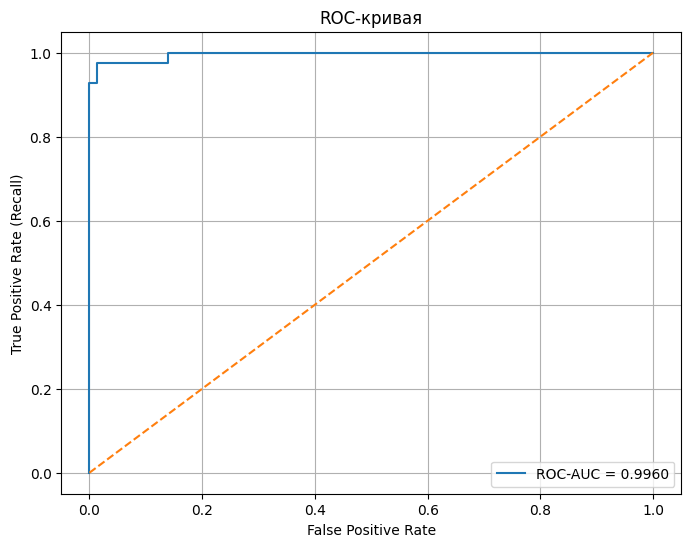

In [9]:
# Строим ROC-кривую

fpr, tpr, thresholds_roc = roc_curve(y_test, y_proba)

roc_auc = roc_auc_score(y_test, y_proba)

print(f"ROC-AUC: {roc_auc:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-кривая")
plt.legend()
plt.grid()
plt.show()

PR-AUC: 0.9942


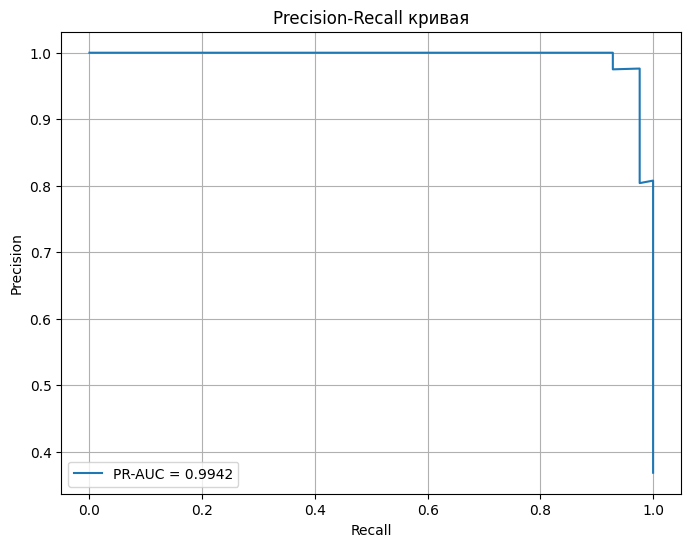

In [10]:
# PR-кривая

precision, recall, thresholds_pr = precision_recall_curve(y_test, y_proba)
pr_auc = auc(recall, precision)

print(f"PR-AUC: {pr_auc:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.4f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall кривая")
plt.legend()
plt.grid()
plt.show()

In [11]:
# Функция для расчёта метрик

def calculate_metrics(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


# 1. Метрики при стандартном пороге 0.50

default_metrics = calculate_metrics(
    y_test,
    y_proba,
    0.50
)


# 2. Перебираем разные пороги

results = []

for threshold in np.arange(0.01, 1.00, 0.01):
    metrics = calculate_metrics(
        y_test,
        y_proba,
        threshold
    )

    if metrics["Recall"] >= 0.95:
        results.append(metrics)


# 3. Выбираем порог с максимальным F1-score

best_result = max(
    results,
    key=lambda x: x["F1-score"]
)

best_threshold = best_result["Threshold"]


# 4. Выводим результаты

print("СТАНДАРТНЫЙ ПОРОГ 0.50")
print("-" * 40)

for key, value in default_metrics.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float) else f"{key}: {value}")


print("\nОПТИМАЛЬНЫЙ ПОРОГ")
print("-" * 40)

for key, value in best_result.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float) else f"{key}: {value}")

СТАНДАРТНЫЙ ПОРОГ 0.50
----------------------------------------
Threshold: 0.5000
Accuracy: 0.9649
Precision: 0.9750
Recall: 0.9286
F1-score: 0.9512
TN: 71
FP: 1
FN: 3
TP: 39

ОПТИМАЛЬНЫЙ ПОРОГ
----------------------------------------
Threshold: 0.2400
Accuracy: 0.9825
Precision: 0.9762
Recall: 0.9762
F1-score: 0.9762
TN: 71
FP: 1
FN: 1
TP: 41


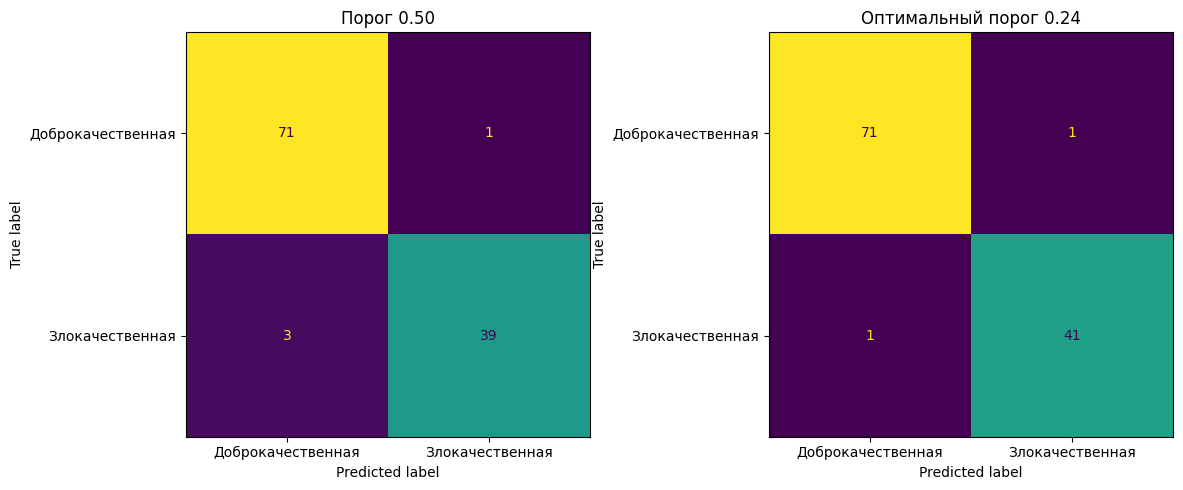

In [12]:
# Матрицы ошибок для двух порогов

y_pred_default = (y_proba >= 0.50).astype(int)
y_pred_best = (y_proba >= best_threshold).astype(int)

cm_default = confusion_matrix(y_test, y_pred_default)
cm_best = confusion_matrix(y_test, y_pred_best)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    cm_default,
    display_labels=["Доброкачественная", "Злокачественная"]
).plot(ax=axes[0], values_format="d", colorbar=False)

axes[0].set_title("Порог 0.50")

ConfusionMatrixDisplay(
    cm_best,
    display_labels=["Доброкачественная", "Злокачественная"]
).plot(ax=axes[1], values_format="d", colorbar=False)

axes[1].set_title(f"Оптимальный порог {best_threshold:.2f}")

plt.tight_layout()
plt.show()

In [13]:
# Итоговое сравнение порогов

comparison = pd.DataFrame([
    {
        "Порог": 0.50,
        "Accuracy": default_metrics["Accuracy"],
        "Precision": default_metrics["Precision"],
        "Recall": default_metrics["Recall"],
        "F1-score": default_metrics["F1-score"],
        "TN": default_metrics["TN"],
        "FP": default_metrics["FP"],
        "FN": default_metrics["FN"],
        "TP": default_metrics["TP"]
    },
    {
        "Порог": best_threshold,
        "Accuracy": best_result["Accuracy"],
        "Precision": best_result["Precision"],
        "Recall": best_result["Recall"],
        "F1-score": best_result["F1-score"],
        "TN": best_result["TN"],
        "FP": best_result["FP"],
        "FN": best_result["FN"],
        "TP": best_result["TP"]
    }
])

comparison

,Порог,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,0.50,0.964912,0.97500,0.928571,0.95122,71,1,3,39
1,0.24,0.982456,0.97619,0.976190,0.97619,71,1,1,41
